In [1]:
import warnings
warnings.filterwarnings('ignore')

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.0)
plt.rcParams['figure.dpi'] = 100

# ------------------------- CONFIG -------------------------
RAW_PATH  = 'used_cars_cleaned_07.csv'
OUT_PATH  = 'used_cars_cleaned_08.csv'
LOG_PATH  = 'cleaning_log_08.csv'
REF_YEAR  = 2026            # "today" for vehicle age
MIN_PRICE = 500             # below this = scrap / data-entry error
PRICE_PLACEHOLDER = 9_999_999
MAX_MILEAGE = 400_000       # above this = typo; re-imputed
MAX_REAL_HP = 1000          # >1000 hp is only plausible for hypercars (price > HYPERCAR_PRICE)
HYPERCAR_PRICE = 250_000
MAX_SEATS = 9
PEER_RATIO = 5              # price > 5x or < 1/5 of same make+model+reg_year median = outlier
PEER_MIN_N = 20             # ...but only judged when the peer group has >= this many cars
SENTINELS = {'unknown', 'unlisted', 'none', 'n/a', 'na', 'nan', 'null', ''}
# ----------------------------------------------------------

df_raw = pd.read_csv(RAW_PATH)
print(f'Raw shape   : {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns')
print(f'Memory usage: {df_raw.memory_usage(deep=True).sum() / 1024**2:.1f} MB')
df_raw.head()

Raw shape   : 362,794 rows x 22 columns
Memory usage: 326.2 MB


,make,model,version,price_gbp,mileage_miles,reg_year,fuel,transmission,power_hp,body_type,body_color,doors,seats,previous_owners,drivetrain,emission_class,annual_tax_gbp,condition,seller_type,seller_city,seller_county,co2_gmile
0,Volkswagen,Polo,1.0 EVO Life Euro 6 (s/s) 5dr,13590,27685,2022,Petrol,Manual,79,Hatchback,Grey,5,5,2,Front Wheel Drive,Euro 6,200.00,Used,Trade,New Southgate,Middlesex,198
1,BMW,X5,3.0d Sport Auto 4WD Euro 4 5dr,995,119000,2003,Diesel,Automatic,181,SUV,Black,5,5,4,Four Wheel Drive,Euro 4,445.00,Used,Trade,Northolt,Middlesex,417
2,Audi,S3,2.0 TFSI Sportback S Tronic quattro Euro 6 (s/...,16490,70000,2016,Petrol,Automatic,306,Hatchback,Grey,5,5,4,Four Wheel Drive,Euro 6,225.00,Used,Trade,Canterbury,Kent,240
3,Volvo,XC40,2.0 B3 MHEV Plus Black Edition DCT Auto Euro 6...,31250,4767,2026,Petrol Hybrid,Automatic,161,SUV,Blue,5,5,1,Front Wheel Drive,Euro 6,200.00,Used,Trade,Northampton,Northamptonshire,245
4,Nissan,X-Trail,2.0 dCi Tekna Auto 4WD Euro 5 5dr (AVM),5500,107000,2014,Diesel,Automatic,148,SUV,Grey,5,5,4,Four Wheel Drive,Euro 5,410.00,Used,Trade,EXMOUTH,DEVON,303


In [2]:
schema = pd.DataFrame({
    'dtype': df_raw.dtypes.astype(str),
    'nulls': df_raw.isnull().sum(),
    'n_unique': df_raw.nunique(),
    'sample': [df_raw[c].dropna().unique()[:3].tolist() for c in df_raw.columns],
})
display(schema)

,dtype,nulls,n_unique,sample
make,object,0,131,"[Volkswagen, BMW, Audi]"
model,object,0,1367,"[Polo, X5, S3]"
version,object,0,30902,"[1.0 EVO Life Euro 6 (s/s) 5dr, 3.0d Sport Aut..."
price_gbp,int64,0,29659,"[13590, 995, 16490]"
mileage_miles,int64,0,94897,"[27685, 119000, 70000]"
reg_year,int64,0,76,"[2022, 2003, 2016]"
fuel,object,0,11,"[Petrol, Diesel, Petrol Hybrid]"
transmission,object,0,3,"[Manual, Automatic, Unlisted]"
power_hp,int64,0,591,"[79, 181, 306]"
body_type,object,0,16,"[Hatchback, SUV, MPV]"


In [3]:
n = len(df_raw)
print(f'Exact duplicate rows : {df_raw.duplicated().sum():,}')
const = [c for c in df_raw.columns if df_raw[c].nunique() <= 1]
print(f'Constant columns     : {const}')

print('\nSentinel strings (placeholder for "missing"):')
cat_cols_raw = [c for c in df_raw.columns if not pd.api.types.is_numeric_dtype(df_raw[c])]
rows = []
for c in cat_cols_raw:
    m = df_raw[c].astype(str).str.strip().str.lower().isin(SENTINELS)
    if m.any():
        rows.append((c, int(m.sum()), m.mean() * 100))
display(pd.DataFrame(rows, columns=['column', 'count', 'pct']).sort_values('count', ascending=False))

print('Zero-valued numeric fields:')
zero_rows = [(c, int((df_raw[c] == 0).sum()), (df_raw[c] == 0).mean() * 100)
             for c in ['mileage_miles', 'power_hp', 'previous_owners', 'co2_gmile']]
display(pd.DataFrame(zero_rows, columns=['column', 'zeros', 'pct']))

print('Fuel type where co2_gmile == 0 (expect Electric/Hydrogen):')
print(df_raw.loc[df_raw['co2_gmile'] == 0, 'fuel'].value_counts().to_string())

print('\nText-casing inconsistencies (unique labels before -> after lower/strip):')
for c in ['make', 'model', 'seller_city', 'seller_county']:
    print(f'  {c:<14}: {df_raw[c].nunique():>5,} -> {df_raw[c].astype(str).str.strip().str.lower().nunique():>5,}')

Exact duplicate rows : 885
Constant columns     : ['condition']

Sentinel strings (placeholder for "missing"):


,column,count,pct
6,emission_class,27285,7.52
8,seller_county,7917,2.18
4,body_color,5288,1.46
5,drivetrain,4410,1.22
7,seller_city,3182,0.88
3,body_type,998,0.28
0,version,463,0.13
2,transmission,216,0.06
1,fuel,191,0.05


Zero-valued numeric fields:


,column,zeros,pct
0,mileage_miles,1826,0.50
1,power_hp,5972,1.65
2,previous_owners,15252,4.20
3,co2_gmile,21951,6.05


Fuel type where co2_gmile == 0 (expect Electric/Hydrogen):
fuel
Electric    21921
Unlisted       27
Hydrogen        3

Text-casing inconsistencies (unique labels before -> after lower/strip):
  make          :   131 ->   131
  model         : 1,367 -> 1,367
  seller_city   : 2,808 -> 1,809
  seller_county :   518 ->   367


In [4]:
num_cols = ['price_gbp', 'mileage_miles', 'reg_year', 'power_hp', 'annual_tax_gbp',
            'co2_gmile', 'doors', 'seats', 'previous_owners']
desc = df_raw[num_cols].describe(percentiles=[.01, .25, .5, .75, .99]).T
desc['skew'] = df_raw[num_cols].skew()
display(desc[['mean', 'std', 'min', '1%', '25%', '50%', '75%', '99%', 'max', 'skew']])

,mean,std,min,1%,25%,50%,75%,99%,max,skew
price_gbp,"19,326.59","36,694.56",75.00,"1,400.00","7,995.00","14,690.00","22,995.00","94,500.00","9,999,999.00",92.53
mileage_miles,"48,617.37","37,675.99",0.00,8.00,"17,501.00","42,000.00","73,120.75","150,081.19","1,480,000.00",1.49
reg_year,"2,019.48",5.11,"1,936.00","2,005.00","2,016.00","2,020.00","2,023.00","2,026.00","2,026.00",-1.45
power_hp,177.56,104.27,0.00,0.00,114.00,148.00,201.00,575.00,"1,898.00",2.01
annual_tax_gbp,198.70,90.88,20.00,20.00,200.00,200.00,200.00,760.00,790.00,2.57
co2_gmile,210.94,92.19,0.00,0.00,180.00,209.00,248.00,475.00,959.00,0.11
doors,4.65,0.82,2.00,2.00,5.00,5.00,5.00,5.00,7.00,-2.25
seats,4.97,0.76,2.00,2.00,5.00,5.00,5.00,7.00,18.00,1.33
previous_owners,2.08,1.36,0.00,0.00,1.00,2.00,3.00,6.00,7.00,1.07


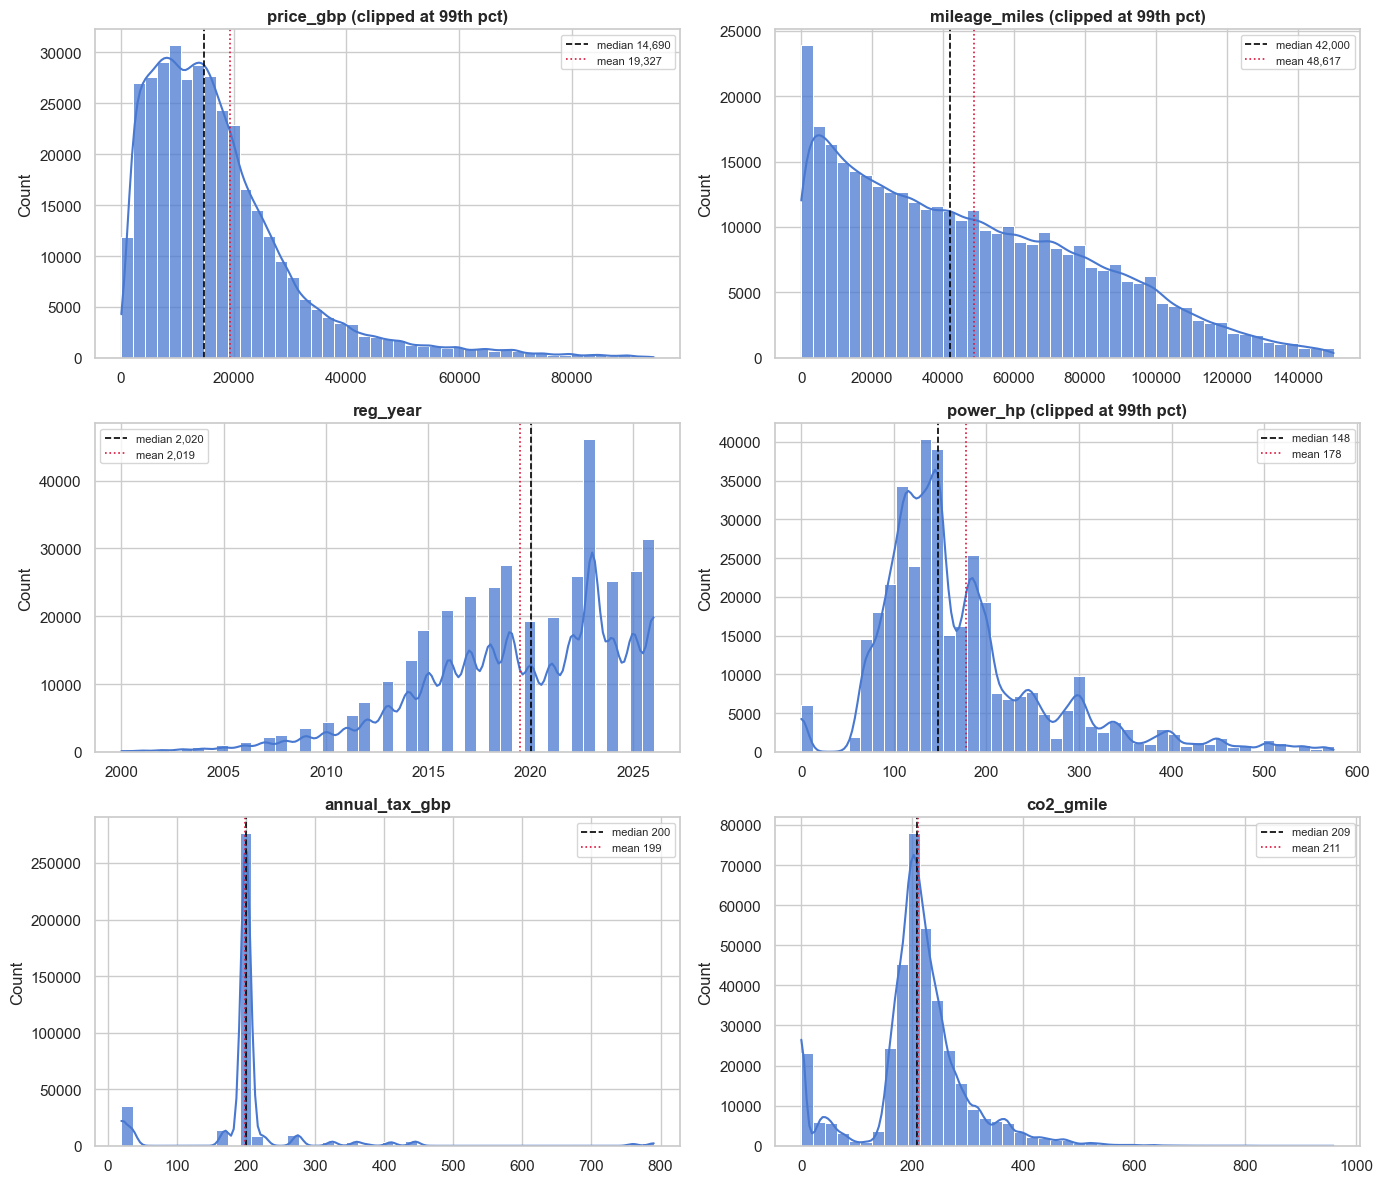

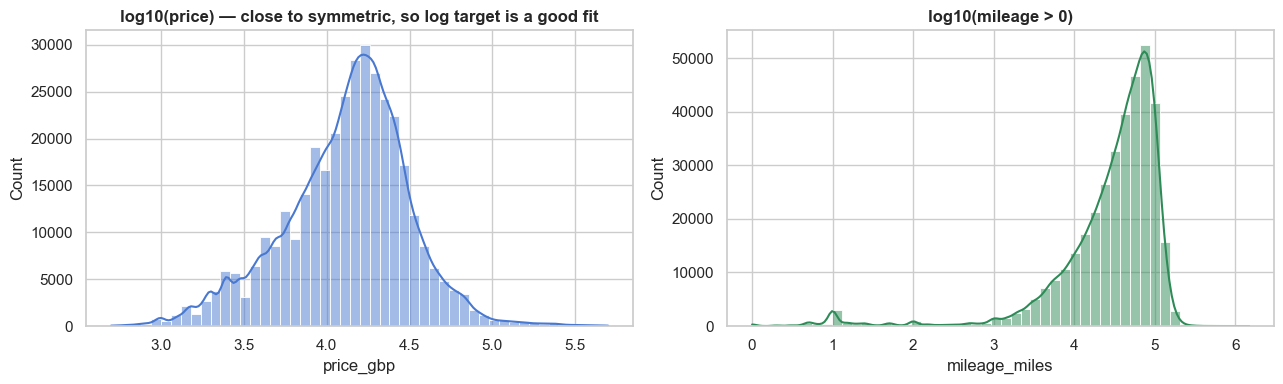

In [5]:
fig, axes = plt.subplots(3, 2, figsize=(14, 12))
specs = [('price_gbp', .99), ('mileage_miles', .99), ('reg_year', None),
         ('power_hp', .99), ('annual_tax_gbp', None), ('co2_gmile', None)]
for ax, (col, q) in zip(axes.flat, specs):
    s = df_raw[col]
    if q: s = s[s <= s.quantile(q)]
    if col == 'reg_year': s = s[s >= 2000]
    sns.histplot(s, bins=45, kde=True, ax=ax, alpha=.75)
    ax.axvline(df_raw[col].median(), color='black', ls='--', lw=1.2, label=f'median {df_raw[col].median():,.0f}')
    ax.axvline(df_raw[col].mean(), color='crimson', ls=':', lw=1.2, label=f'mean {df_raw[col].mean():,.0f}')
    ax.set_title(col + (' (clipped at 99th pct)' if q else ''), fontweight='bold'); ax.set_xlabel(''); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
p = df_raw.loc[df_raw.price_gbp.between(MIN_PRICE, 500_000), 'price_gbp']
sns.histplot(np.log10(p), bins=50, kde=True, ax=axes[0]); axes[0].set_title('log10(price) — close to symmetric, so log target is a good fit', fontweight='bold')
mi = df_raw.loc[df_raw.mileage_miles > 0, 'mileage_miles']
sns.histplot(np.log10(mi), bins=50, kde=True, ax=axes[1], color='seagreen'); axes[1].set_title('log10(mileage > 0)', fontweight='bold')
plt.tight_layout(); plt.show()

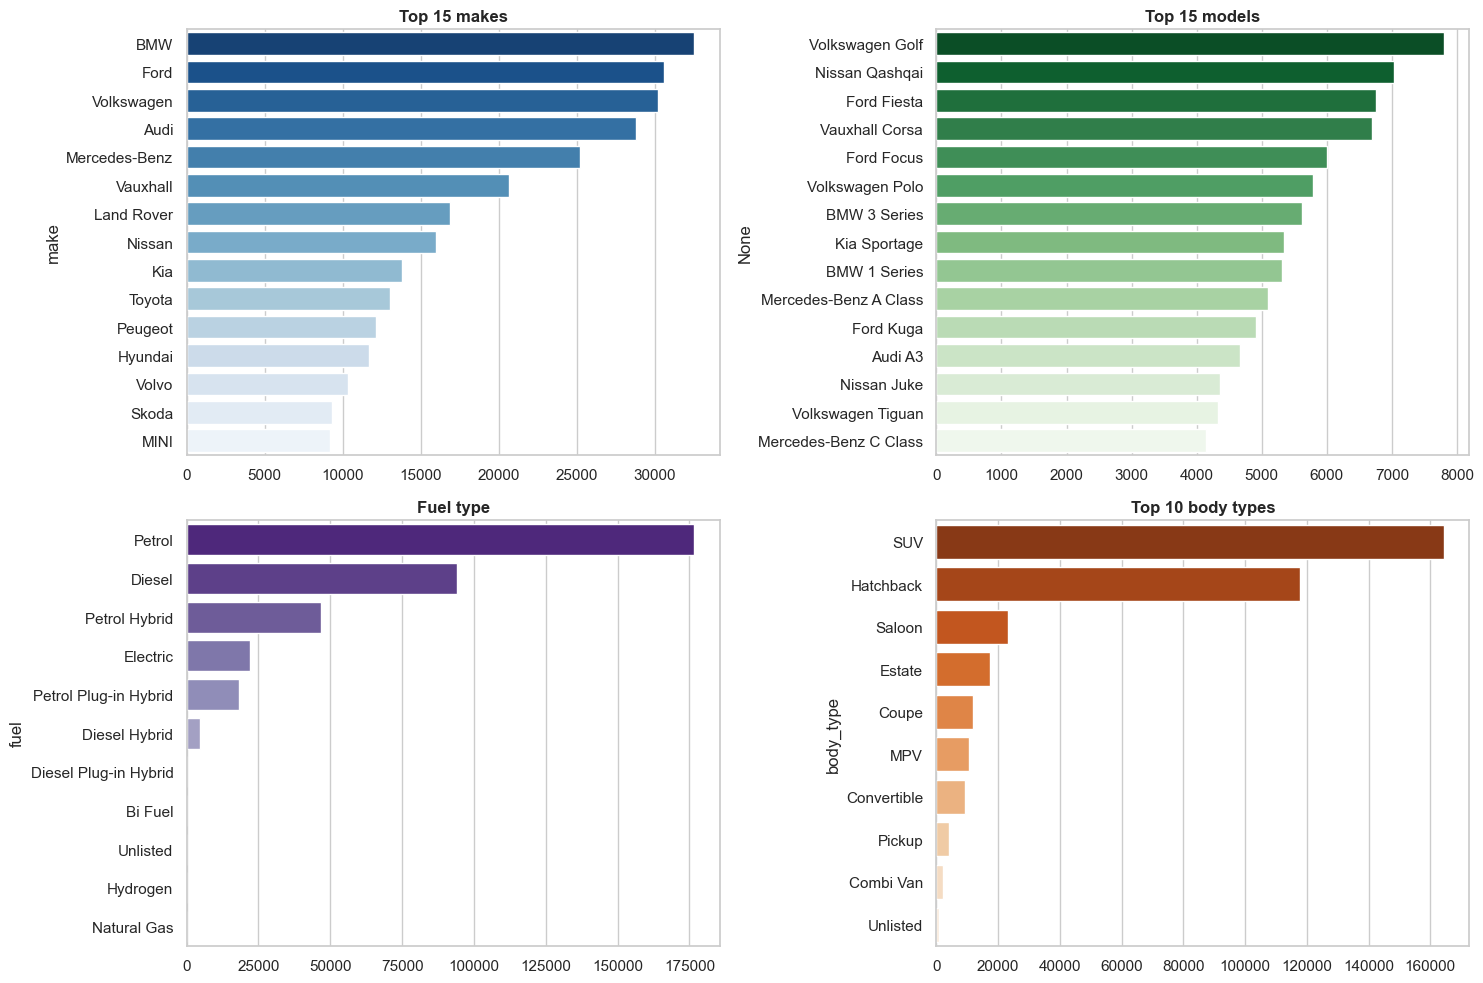

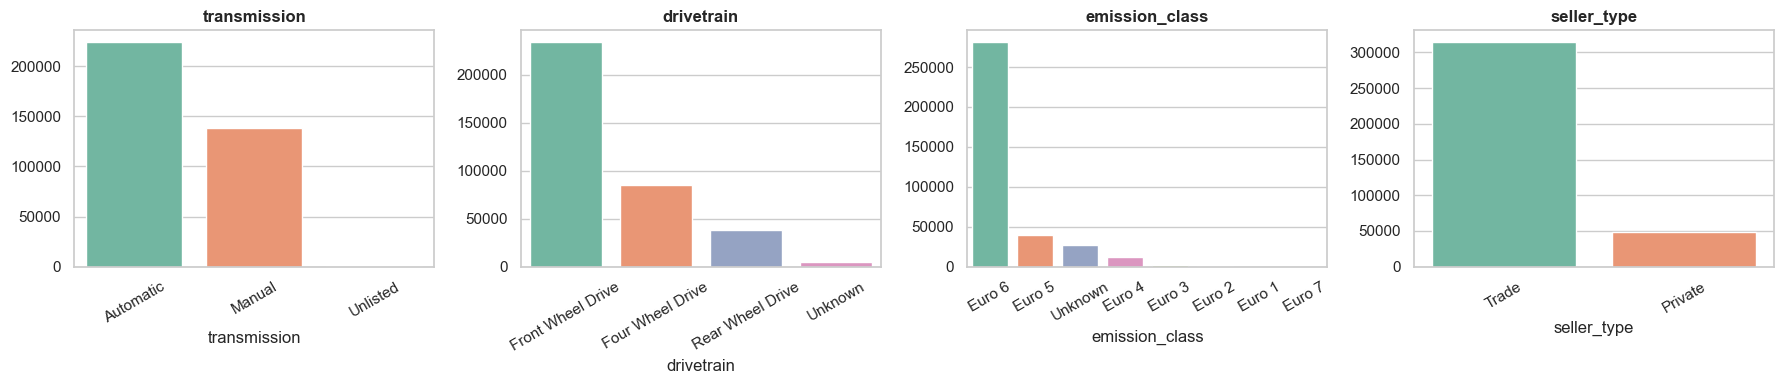

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
sns.barplot(x=df_raw['make'].value_counts().head(15).values, y=df_raw['make'].value_counts().head(15).index, ax=axes[0, 0], palette='Blues_r')
axes[0, 0].set_title('Top 15 makes', fontweight='bold')
tm = (df_raw['make'] + ' ' + df_raw['model']).value_counts().head(15)
sns.barplot(x=tm.values, y=tm.index, ax=axes[0, 1], palette='Greens_r'); axes[0, 1].set_title('Top 15 models', fontweight='bold')
fc = df_raw['fuel'].value_counts()
sns.barplot(x=fc.values, y=fc.index, ax=axes[1, 0], palette='Purples_r'); axes[1, 0].set_title('Fuel type', fontweight='bold')
bc = df_raw['body_type'].value_counts().head(10)
sns.barplot(x=bc.values, y=bc.index, ax=axes[1, 1], palette='Oranges_r'); axes[1, 1].set_title('Top 10 body types', fontweight='bold')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, ['transmission', 'drivetrain', 'emission_class', 'seller_type']):
    vc = df_raw[c].value_counts()
    sns.barplot(x=vc.index, y=vc.values, ax=ax, palette='Set2'); ax.set_title(c, fontweight='bold')
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

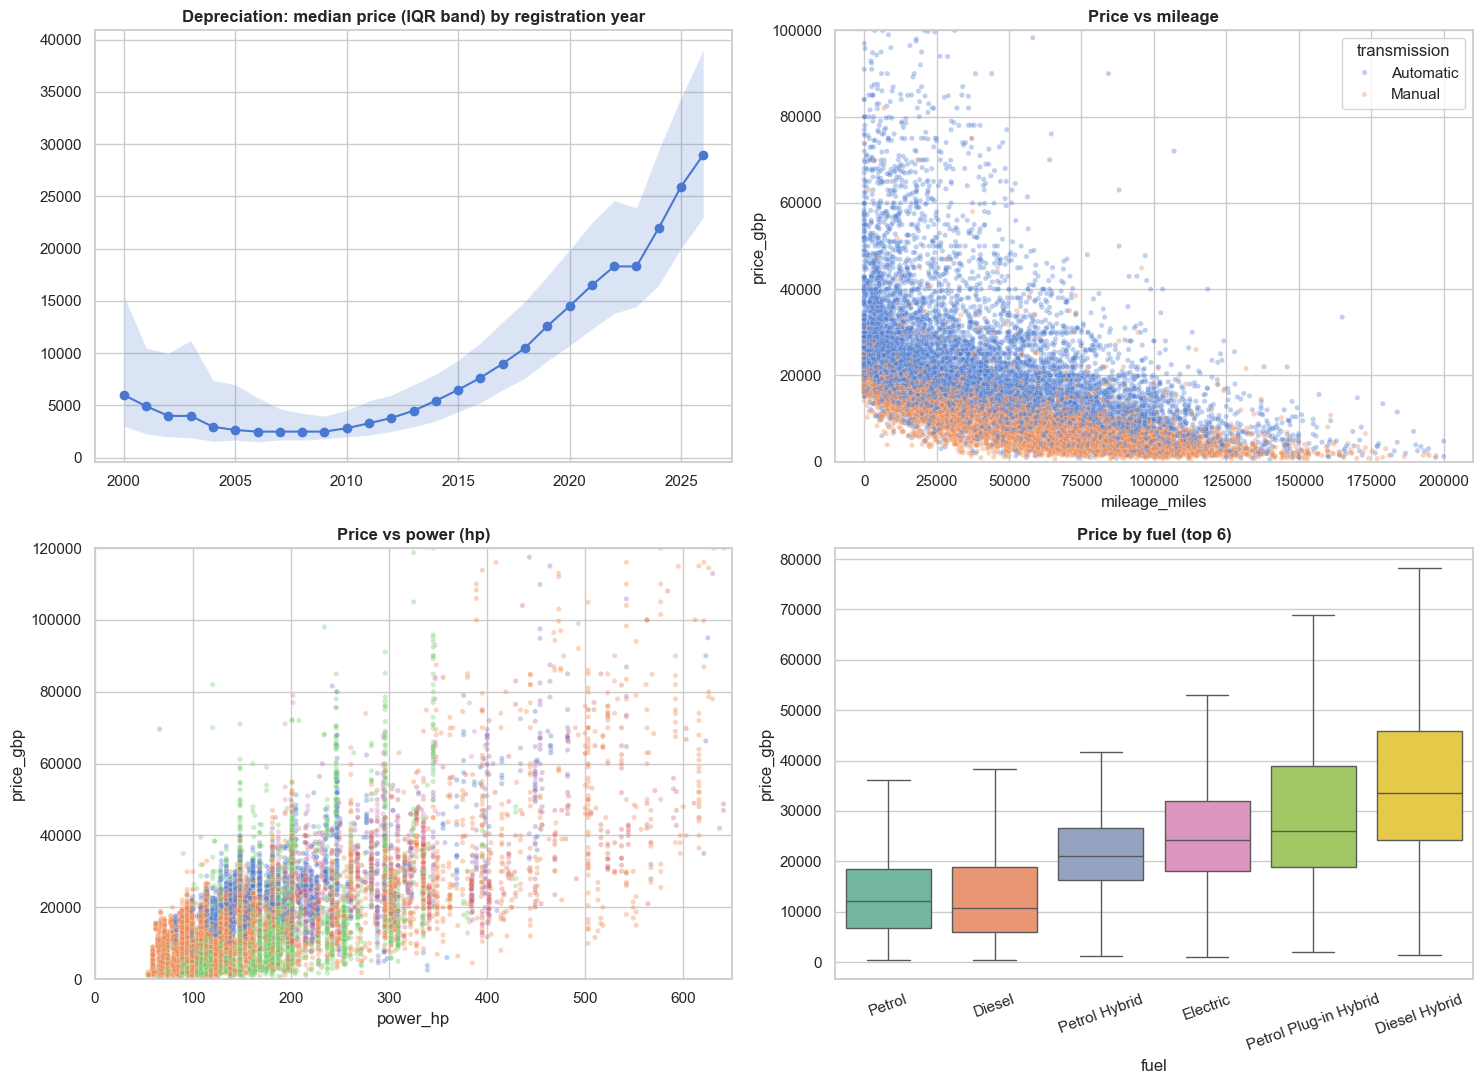

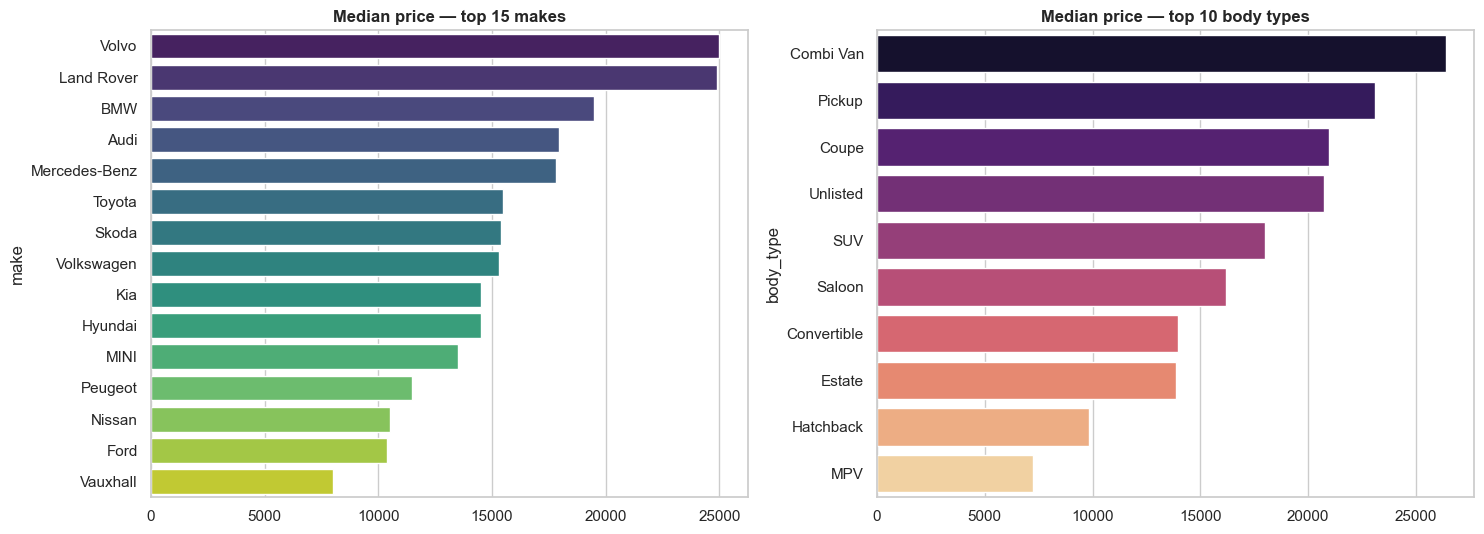

In [7]:
sl = df_raw[df_raw.price_gbp.between(MIN_PRICE, HYPERCAR_PRICE) & (df_raw.reg_year >= 2000)]
samp = sl[(sl.mileage_miles <= 200_000) & (sl.power_hp > 0)].sample(min(15_000, len(sl)), random_state=42)

fig, axes = plt.subplots(2, 2, figsize=(15, 11))
ys = sl.groupby('reg_year')['price_gbp'].agg(median='median', q25=lambda x: x.quantile(.25), q75=lambda x: x.quantile(.75))
axes[0, 0].plot(ys.index, ys['median'], marker='o'); axes[0, 0].fill_between(ys.index, ys.q25, ys.q75, alpha=.2)
axes[0, 0].set_title('Depreciation: median price (IQR band) by registration year', fontweight='bold')
sns.scatterplot(data=samp, x='mileage_miles', y='price_gbp', hue='transmission', alpha=.35, s=14, ax=axes[0, 1])
axes[0, 1].set_ylim(0, 100_000); axes[0, 1].set_title('Price vs mileage', fontweight='bold')
sns.scatterplot(data=samp, x='power_hp', y='price_gbp', hue='fuel', alpha=.35, s=14, ax=axes[1, 0], legend=False)
axes[1, 0].set_xlim(0, 650); axes[1, 0].set_ylim(0, 120_000); axes[1, 0].set_title('Price vs power (hp)', fontweight='bold')
top_f = sl.fuel.value_counts().head(6).index
sns.boxplot(data=sl[sl.fuel.isin(top_f)], x='fuel', y='price_gbp', showfliers=False, ax=axes[1, 1], palette='Set2')
axes[1, 1].tick_params(axis='x', rotation=20); axes[1, 1].set_title('Price by fuel (top 6)', fontweight='bold')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
mk = sl[sl.make.isin(sl.make.value_counts().head(15).index)].groupby('make')['price_gbp'].median().sort_values(ascending=False)
sns.barplot(x=mk.values, y=mk.index, ax=axes[0], palette='viridis'); axes[0].set_title('Median price — top 15 makes', fontweight='bold')
bt = sl[sl.body_type.isin(sl.body_type.value_counts().head(10).index)].groupby('body_type')['price_gbp'].median().sort_values(ascending=False)
sns.barplot(x=bt.values, y=bt.index, ax=axes[1], palette='magma'); axes[1].set_title('Median price — top 10 body types', fontweight='bold')
plt.tight_layout(); plt.show()

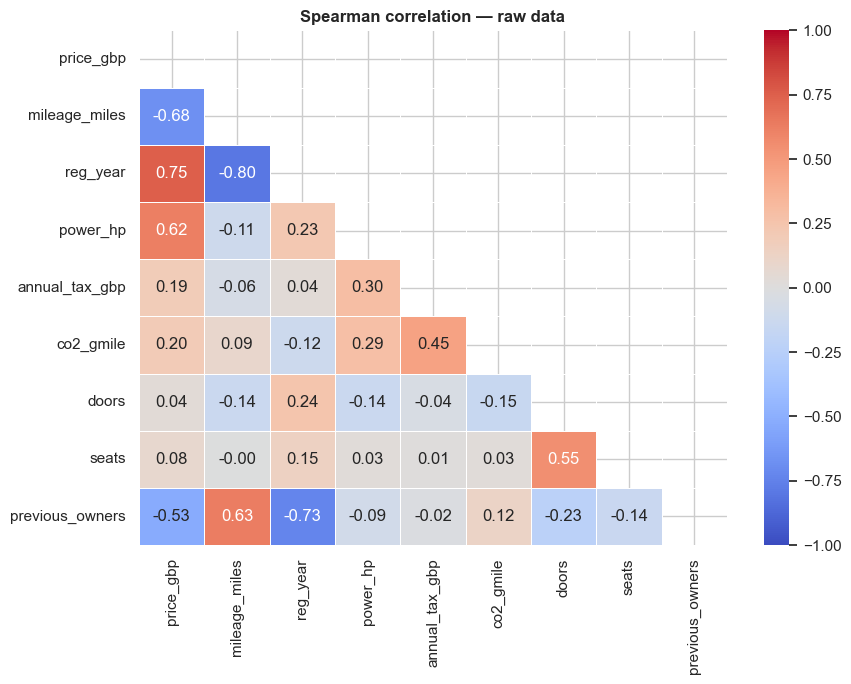

In [8]:
corr = df_raw[num_cols].corr(method='spearman')
plt.figure(figsize=(9, 7))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool)), annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, linewidths=.5)
plt.title('Spearman correlation — raw data', fontweight='bold'); plt.tight_layout(); plt.show()

In [9]:
print(f'price < £{MIN_PRICE:,}            : {(df_raw.price_gbp < MIN_PRICE).sum():,}')
print(f'price > £{HYPERCAR_PRICE:,}          : {(df_raw.price_gbp > HYPERCAR_PRICE).sum():,}')
print(f'price == £{PRICE_PLACEHOLDER:,}     : {(df_raw.price_gbp == PRICE_PLACEHOLDER).sum():,}')
print(f'mileage > {MAX_MILEAGE:,}          : {(df_raw.mileage_miles > MAX_MILEAGE).sum():,}')
print(f'power_hp > {MAX_REAL_HP:,}            : {(df_raw.power_hp > MAX_REAL_HP).sum():,}')
print(f'seats > {MAX_SEATS}                  : {(df_raw.seats > MAX_SEATS).sum():,}')
print(f'doors > 5                  : {(df_raw.doors > 5).sum():,}')
print(f'reg_year > {REF_YEAR}            : {(df_raw.reg_year > REF_YEAR).sum():,}')
print(f'reg_year < 2000 (classics) : {(df_raw.reg_year < 2000).sum():,}')
df_raw.nlargest(5, 'price_gbp')[['make', 'model', 'version', 'reg_year', 'mileage_miles', 'price_gbp']]

price < £500            : 90
price > £250,000          : 620
price == £9,999,999     : 1
mileage > 400,000          : 23
power_hp > 1,000            : 27
seats > 9                  : 146
doors > 5                  : 1,104
reg_year > 2026            : 0
reg_year < 2000 (classics) : 1,048


,make,model,version,reg_year,mileage_miles,price_gbp
84760,Ferrari,F40,2.9 Coupe 2dr Petrol Manual (478 bhp),1992,8500,9999999
57767,Bugatti,Chiron,Unknown,2022,2800,5000000
167514,Bugatti,Chiron,Unknown,2021,800,5000000
311042,Bugatti,Chiron,Unknown,2023,3100,4800000
288010,Ferrari,F40,2.9 2dr,1991,9259,3694995


In [10]:
clean_log = []
def log(step, removed=0, changed=0, detail=''):
    clean_log.append({'step': step, 'rows_removed': int(removed), 'values_changed': int(changed), 'detail': detail})
    print(f'[{step}] removed={removed:,}  changed={changed:,}  {detail}')

df = df_raw.copy()
def text_cols(d):
    return [c for c in d.columns if not pd.api.types.is_numeric_dtype(d[c])]

cat_cols = text_cols(df)
print('Starting rows:', f'{len(df):,}')

Starting rows: 362,794


In [11]:
def canonicalize(s):
    # map every case/whitespace variant to its most frequent spelling
    s = s.astype(str).str.strip().str.replace(r'\s+', ' ', regex=True)
    vc = s.value_counts()                         # sorted by frequency
    canon = pd.Series(vc.index, index=vc.index.str.lower())
    canon = canon[~canon.index.duplicated()]      # keep the most frequent spelling
    return s.str.lower().map(canon)

def smart_title(x):
    # 'bishop's stortford' -> "Bishop's Stortford" (str.title() would give "Bishop'S")
    return re.sub(r"(^|[\s\-/(])([a-z])", lambda m: m.group(1) + m.group(2).upper(), x.lower())

before = {c: df[c].nunique() for c in ['make', 'model', 'seller_city', 'seller_county']}
for c in ['make', 'model', 'fuel', 'transmission', 'body_type', 'body_color', 'drivetrain', 'emission_class', 'seller_type']:
    df[c] = canonicalize(df[c])
df['version'] = df['version'].astype(str).str.strip().str.replace(r'\s+', ' ', regex=True)
for c in ['seller_city', 'seller_county']:
    s = df[c].astype(str).str.strip().str.replace(r'\s+', ' ', regex=True)
    df[c] = s.map({u: smart_title(u) for u in s.unique()})
after = {c: df[c].nunique() for c in before}
log('text_normalisation', changed=sum(before[c] - after[c] for c in before),
    detail=f'unique labels {before} -> {after}')

[text_normalisation] removed=0  changed=1,150  unique labels {'make': 131, 'model': 1367, 'seller_city': 2808, 'seller_county': 518} -> {'make': 131, 'model': 1367, 'seller_city': 1809, 'seller_county': 367}


In [12]:
for c in cat_cols:
    if c == 'version':
        continue
    m = df[c].astype(str).str.strip().str.lower().isin(SENTINELS)
    df.loc[m, c] = np.nan
df.loc[df['version'].str.lower().isin(SENTINELS), 'version'] = 'Unknown'
miss_after_sentinel = df[cat_cols].isna().sum()
log('sentinel_to_nan', changed=int(miss_after_sentinel.sum()), detail=miss_after_sentinel[miss_after_sentinel > 0].to_dict().__str__())

[sentinel_to_nan] removed=0  changed=49,487  {'fuel': 191, 'transmission': 216, 'body_type': 998, 'body_color': 5288, 'drivetrain': 4410, 'emission_class': 27285, 'seller_city': 3182, 'seller_county': 7917}


In [13]:
const_cols = [c for c in text_cols(df) if df[c].nunique(dropna=False) <= 1]   # only text columns (numeric ones stay)
df = df.drop(columns=const_cols)
cat_cols = [c for c in cat_cols if c not in const_cols]
n0 = len(df)
df = df.drop_duplicates().reset_index(drop=True)
log('drop_constant_columns', detail=str(const_cols))
log('drop_duplicates', removed=n0 - len(df), detail='exact duplicates after normalisation')

[drop_constant_columns] removed=0  changed=0  ['condition']
[drop_duplicates] removed=886  changed=0  exact duplicates after normalisation


In [14]:
bad_year    = (df.reg_year > REF_YEAR) | (df.reg_year < 1900)
placeholder = df.price_gbp >= PRICE_PLACEHOLDER
too_cheap   = df.price_gbp < MIN_PRICE
drop = bad_year | placeholder | too_cheap
n0 = len(df)
df = df[~drop].reset_index(drop=True)
log('drop_invalid_rows', removed=n0 - len(df),
    detail=f'future/absurd year={int(bad_year.sum())}, placeholder price={int(placeholder.sum())}, price<{MIN_PRICE}={int(too_cheap.sum())}')
df['vehicle_age'] = (REF_YEAR - df['reg_year']).clip(lower=0)

[drop_invalid_rows] removed=91  changed=0  future/absurd year=0, placeholder price=1, price<500=90


In [15]:
def fill_by_group_mode(d, col, key_sets, min_n=3):
    for keys in key_sets:
        miss = d[col].isna()
        if not miss.any():
            break
        known = d.loc[~miss, keys + [col]].dropna(subset=keys)
        cnt = known.groupby(keys + [col]).size().rename('n').reset_index()
        tot = cnt.groupby(keys)['n'].transform('sum')
        cnt = cnt[tot >= min_n].sort_values('n', ascending=False).drop_duplicates(keys)
        lookup = cnt.rename(columns={col: '_fill'})[keys + ['_fill']]
        d.loc[miss, col] = d.loc[miss, keys].merge(lookup, on=keys, how='left')['_fill'].values

def fill_by_group_median(d, col, key_sets, min_n=3):
    for keys in key_sets:
        g = d.groupby(keys)[col]
        d[col] = d[col].fillna(g.transform('median').where(g.transform('count') >= min_n))

In [16]:
def infer_from_version(d, col, rules):
    # rules: list of (regex, label); applied only to rows where col is NaN
    miss = d[col].isna()
    v = d.loc[miss, 'version'].str.lower()
    out = pd.Series(np.nan, index=v.index, dtype=object)
    for pattern, label in rules:
        if label is None:
            continue
        hit = out.isna() & v.str.contains(pattern, regex=True)
        out[hit] = label
    d.loc[miss, col] = out.values

cat_missing_start = df[cat_cols].isna().sum()
df['emission_class_imputed'] = df['emission_class'].isna().astype('int8')

# ---- fuel: label named in the version text, or co2 == 0 => Electric
fuel_labels = sorted(df['fuel'].dropna().unique(), key=len, reverse=True)    # longest first ('Petrol Hybrid' before 'Petrol')
infer_from_version(df, 'fuel', [(r'\b' + re.escape(l.lower()) + r'\b', l) for l in fuel_labels])
if 'Electric' in fuel_labels:
    df.loc[df['fuel'].isna() & (df['co2_gmile'] == 0), 'fuel'] = 'Electric'
df['fuel'] = df['fuel'].fillna('Unknown')

# ---- transmission
auto_re = r'\b(?:auto|dct|dsg|cvt|e-cvt|s[- ]?tronic|tiptronic|steptronic|multitronic|powershift|edc|pdk|tct)\b'
infer_from_version(df, 'transmission', [(auto_re, 'Automatic' if 'Automatic' in set(df.transmission.dropna()) else None),
                                        (r'\bmanual\b', 'Manual' if 'Manual' in set(df.transmission.dropna()) else None)])
fill_by_group_mode(df, 'transmission', [['make', 'model', 'version']])

# ---- body type
fill_by_group_mode(df, 'body_type', [['make', 'model', 'version'], ['make', 'model']])

# ---- drivetrain
four = next((l for l in df.drivetrain.dropna().unique() if 'four' in l.lower()), None)
infer_from_version(df, 'drivetrain', [(r'\b(?:4wd|awd|4x4|quattro|xdrive|4matic|4motion)\b', four)])
fill_by_group_mode(df, 'drivetrain', [['make', 'model', 'version'], ['make', 'model']])

# ---- emission class: "Euro N" in version text, else most common class for that registration year + fuel
euro_labels = set(df.emission_class.dropna().unique())
ev = df['emission_class'].isna()
num = df.loc[ev, 'version'].str.extract(r'(?i)euro\s*(\d)')[0]
cand = ('Euro ' + num)
df.loc[ev, 'emission_class'] = cand.where(cand.isin(euro_labels)).values
fill_by_group_mode(df, 'emission_class', [['reg_year', 'fuel'], ['reg_year']], min_n=5)

# ---- county from city (same city name -> same county)
fill_by_group_mode(df, 'seller_county', [['seller_city']], min_n=2)

# ---- whatever cannot be inferred becomes an explicit category
for c in cat_cols:
    df[c] = df[c].fillna('Unknown')

cat_missing_end = (df[cat_cols] == 'Unknown').sum()
rep = pd.DataFrame({'missing_before': cat_missing_start, 'unknown_after': cat_missing_end})
display(rep[(rep.missing_before > 0) | (rep.unknown_after > 0)])
log('categorical_imputation', changed=int(cat_missing_start.sum() - cat_missing_end.sum()),
    detail='inferred from version text / peers; remainder = "Unknown"')

,missing_before,unknown_after
version,0,463
fuel,179,74
transmission,216,105
body_type,992,174
body_color,5029,5029
drivetrain,4393,555
emission_class,27043,429
seller_city,3180,3180
seller_county,7900,3260


[categorical_imputation] removed=0  changed=35,663  inferred from version text / peers; remainder = "Unknown"


In [17]:
is_ev = df['fuel'].isin(['Electric', 'Hydrogen'])
age = df['vehicle_age']

# ---- mileage: 0 on a car >= 2 yrs old, or absurdly high => missing
m_bad = ((df.mileage_miles == 0) & (age >= 2)) | (df.mileage_miles > MAX_MILEAGE)
df['mileage_imputed'] = m_bad.astype('int8')
df.loc[m_bad, 'mileage_miles'] = np.nan
fill_by_group_median(df, 'mileage_miles', [['reg_year', 'make'], ['reg_year']], min_n=5)
df['mileage_miles'] = df['mileage_miles'].fillna(df['mileage_miles'].median()).round().astype('int64')
log('mileage_fix', changed=int(m_bad.sum()), detail='0 miles on >=2-yr-old cars, or > MAX_MILEAGE')

# ---- power: 0, or > 1000 hp on a non-hypercar => missing
p_bad = (df.power_hp == 0) | ((df.power_hp > MAX_REAL_HP) & (df.price_gbp < HYPERCAR_PRICE))
df['power_hp_imputed'] = p_bad.astype('int8')
df.loc[p_bad, 'power_hp'] = np.nan
hp_keys = [['make', 'model', 'version', 'fuel'], ['make', 'model', 'fuel'], ['make', 'fuel'], ['fuel']]
fill_by_group_median(df, 'power_hp', hp_keys)
df['power_hp'] = df['power_hp'].fillna(df['power_hp'].median()).round().astype('int64')
log('power_fix', changed=int(p_bad.sum()), detail='0 hp or > MAX_REAL_HP on non-hypercars')

# ---- CO2: electric/hydrogen must be 0; combustion cars with 0 are missing
ev_wrong = is_ev & (df.co2_gmile != 0)
df.loc[is_ev, 'co2_gmile'] = 0
c_bad = (~is_ev) & (df.fuel != 'Unknown') & (df.co2_gmile == 0)
df['co2_imputed'] = c_bad.astype('int8')
df.loc[c_bad, 'co2_gmile'] = np.nan
fill_by_group_median(df, 'co2_gmile', hp_keys)
df['co2_gmile'] = df['co2_gmile'].fillna(df.loc[~is_ev, 'co2_gmile'].median()).round().astype('int64')
log('co2_fix', changed=int(c_bad.sum() + ev_wrong.sum()), detail=f'ICE zeros imputed={int(c_bad.sum())}, EV forced to 0={int(ev_wrong.sum())}')

# ---- previous owners: 0 on a car >= 2 yrs old => unrecorded
o_bad = (df.previous_owners == 0) & (age >= 2)
df['previous_owners_imputed'] = o_bad.astype('int8')
df.loc[o_bad, 'previous_owners'] = np.nan
fill_by_group_median(df, 'previous_owners', [['reg_year']], min_n=5)
df['previous_owners'] = df['previous_owners'].fillna(df['previous_owners'].median()).round().astype('int64')
log('previous_owners_fix', changed=int(o_bad.sum()), detail='0 owners on >=2-yr-old cars')

# ---- seats / doors out of range
s_bad = (df.seats > MAX_SEATS) | (df.seats < 2)
df.loc[s_bad, 'seats'] = np.nan
fill_by_group_mode(df, 'seats', [['make', 'model', 'version'], ['make', 'model']])
df['seats'] = df['seats'].fillna(df['seats'].mode().iloc[0]).astype('int64')
d_bad = (df.doors > 5) | (df.doors < 2)
df.loc[d_bad, 'doors'] = np.nan
fill_by_group_mode(df, 'doors', [['make', 'model', 'body_type'], ['make', 'model']])
df['doors'] = df['doors'].fillna(df['doors'].mode().iloc[0]).astype('int64')
log('seats_doors_fix', changed=int(s_bad.sum() + d_bad.sum()), detail=f'seats={int(s_bad.sum())}, doors={int(d_bad.sum())}')

[mileage_fix] removed=0  changed=58  0 miles on >=2-yr-old cars, or > MAX_MILEAGE
[power_fix] removed=0  changed=5,964  0 hp or > MAX_REAL_HP on non-hypercars
[co2_fix] removed=0  changed=31  ICE zeros imputed=0, EV forced to 0=31
[previous_owners_fix] removed=0  changed=9,426  0 owners on >=2-yr-old cars
[seats_doors_fix] removed=0  changed=1,244  seats=146, doors=1098


In [18]:
grp = df.groupby(['make', 'model', 'reg_year'])['price_gbp']
peer_med = grp.transform('median')
peer_n = grp.transform('count')
ratio = df['price_gbp'] / peer_med
peer_out = (peer_n >= PEER_MIN_N) & ((ratio > PEER_RATIO) | (ratio < 1 / PEER_RATIO))
print('Examples of removed rows:')
display(df.loc[peer_out, ['make', 'model', 'reg_year', 'mileage_miles', 'price_gbp']].assign(peer_median=peer_med[peer_out]).head(10))
n0 = len(df)
df = df[~peer_out].reset_index(drop=True)
log('drop_price_peer_outliers', removed=n0 - len(df), detail=f'price > {PEER_RATIO}x or < 1/{PEER_RATIO} of peer median (peer n >= {PEER_MIN_N})')
# imputation can make two listings identical -> dedupe again
n0 = len(df)
df = df.drop_duplicates().reset_index(drop=True)
log('drop_duplicates_post_imputation', removed=n0 - len(df), detail='duplicates created by imputation')
print(f'Genuine luxury cars kept: {(df.price_gbp > HYPERCAR_PRICE).sum():,} listings above £{HYPERCAR_PRICE:,}')

Examples of removed rows:


,make,model,reg_year,mileage_miles,price_gbp,peer_median
4569,Renault,Clio,2010,34501,10950,"1,800.00"
4584,MINI,Hatch,2006,70800,13999,"2,195.00"
5711,Vauxhall,Astra,2009,43000,13995,"1,892.50"
6394,BMW,5 Series,2011,125000,1000,"5,995.00"
10405,BMW,1 Series,2011,49000,42990,"3,447.50"
15894,Ford,Focus,2017,5284,35995,"6,445.00"
17060,Ford,Focus,2009,65767,20080,"1,995.00"
17489,Ford,Focus,2016,44000,26900,"5,345.00"
19686,Mercedes-Benz,C Class,2009,14000,31995,"3,250.00"
21685,Mercedes-Benz,C Class,2012,50300,25000,"4,990.00"


[drop_price_peer_outliers] removed=226  changed=0  price > 5x or < 1/5 of peer median (peer n >= 20)
[drop_duplicates_post_imputation] removed=1  changed=0  duplicates created by imputation
Genuine luxury cars kept: 594 listings above £250,000


In [19]:
df['log_price'] = np.log1p(df['price_gbp'])
df['vehicle_age'] = (REF_YEAR - df['reg_year']).clip(lower=0)
df['miles_per_year'] = (df['mileage_miles'] / df['vehicle_age'].clip(lower=1)).round(1)

# engine size (litres) from the version string, e.g. "2.0 TFSI ..." or "3.0d ..."
eng = df['version'].str.extract(r'(?<![\d.])(\d\.\d)(?=\D|$)')[0].astype(float)
eng = eng.where(eng.between(0.6, 8.5))
eng[df['fuel'].isin(['Electric', 'Hydrogen'])] = 0.0
df['engine_size_l'] = eng
fill_by_group_median(df, 'engine_size_l', [['make', 'model', 'fuel'], ['make', 'fuel'], ['fuel']])
df['engine_size_l'] = df['engine_size_l'].fillna(df['engine_size_l'].median())

# performance / sport trims
perf_re = r'\b(?:amg|m sport|m performance|gti|gtd|s line|st-line|r-line|type r|cupra|abarth|vxr|vrs)\b'
df['is_performance_trim'] = df['version'].str.lower().str.contains(perf_re, regex=True).astype('int8')

df['is_high_value'] = (df['price_gbp'] > HYPERCAR_PRICE).astype('int8')   # real luxury cars, flagged not dropped
df['is_classic'] = (df['reg_year'] < 2000).astype('int8')
log('derived_columns', changed=0, detail='log_price, vehicle_age, miles_per_year, engine_size_l, is_performance_trim, is_high_value, is_classic')
print(f'Rows kept: {len(df):,} of {len(df_raw):,} ({len(df) / len(df_raw):.2%})')

[derived_columns] removed=0  changed=0  log_price, vehicle_age, miles_per_year, engine_size_l, is_performance_trim, is_high_value, is_classic
Rows kept: 361,590 of 362,794 (99.67%)


In [20]:
checks = {
    'no missing values':                 df.isna().sum().sum() == 0,
    'no duplicate rows':                 df.duplicated().sum() == 0,
    'no constant text columns':          all(df[c].nunique() > 1 for c in cat_cols if c in df.columns),
    'price within [MIN_PRICE, placeholder)': df.price_gbp.between(MIN_PRICE, PRICE_PLACEHOLDER - 1).all(),
    'reg_year <= REF_YEAR':              (df.reg_year <= REF_YEAR).all(),
    'power_hp > 0':                      (df.power_hp > 0).all(),
    'non-EV co2 > 0 (known fuel)':       (df.loc[~df.fuel.isin(['Electric', 'Hydrogen', 'Unknown']), 'co2_gmile'] > 0).all(),
    'EV co2 == 0':                       (df.loc[df.fuel.isin(['Electric', 'Hydrogen']), 'co2_gmile'] == 0).all(),
    'seats in [2, MAX_SEATS]':           df.seats.between(2, MAX_SEATS).all(),
    'doors in [2, 5]':                   df.doors.between(2, 5).all(),
    'mileage <= MAX_MILEAGE':            (df.mileage_miles <= MAX_MILEAGE).all(),
    'no leftover sentinels (Unlisted)':  not df[cat_cols].apply(lambda s: s.str.lower().eq('unlisted')).any().any(),
}
for k, v in checks.items():
    print(('PASS  ' if v else 'FAIL  ') + k)
failed = [k for k, v in checks.items() if not v]
assert not failed, f'Failed checks: {failed}'

PASS  no missing values
PASS  no duplicate rows
PASS  no constant text columns
PASS  price within [MIN_PRICE, placeholder)
PASS  reg_year <= REF_YEAR
PASS  power_hp > 0
PASS  non-EV co2 > 0 (known fuel)
PASS  EV co2 == 0
PASS  seats in [2, MAX_SEATS]
PASS  doors in [2, 5]
PASS  mileage <= MAX_MILEAGE
PASS  no leftover sentinels (Unlisted)


In [21]:
def summary(d):
    return pd.Series({
        'rows': len(d), 'columns': d.shape[1],
        'price max (£)': d.price_gbp.max(), 'price skew': d.price_gbp.skew(),
        'zero power_hp': (d.power_hp == 0).sum(),
        'zero mileage': (d.mileage_miles == 0).sum(),
        'zero previous_owners': (d.previous_owners == 0).sum(),
        'seats > 9': (d.seats > MAX_SEATS).sum(),
        'sentinel cells (Unknown/Unlisted)': int(d[[c for c in d.columns if not pd.api.types.is_numeric_dtype(d[c])]].apply(lambda s: s.str.lower().isin(['unknown', 'unlisted'])).sum().sum()),
        'duplicate rows': d.duplicated().sum(),
    })
cmp = pd.DataFrame({'raw': summary(df_raw), 'cleaned': summary(df)})
display(cmp)
print('log_price skew after cleaning:', round(df['log_price'].skew(), 3))

,raw,cleaned
rows,"362,794.00","361,590.00"
columns,22.00,33.00
price max (£),"9,999,999.00","5,000,000.00"
price skew,92.53,53.26
zero power_hp,"5,972.00",0.00
zero mileage,"1,826.00","1,721.00"
zero previous_owners,"15,252.00","5,736.00"
seats > 9,146.00,0.00
sentinel cells (Unknown/Unlisted),"49,950.00","13,261.00"
duplicate rows,885.00,0.00


log_price skew after cleaning: -0.281


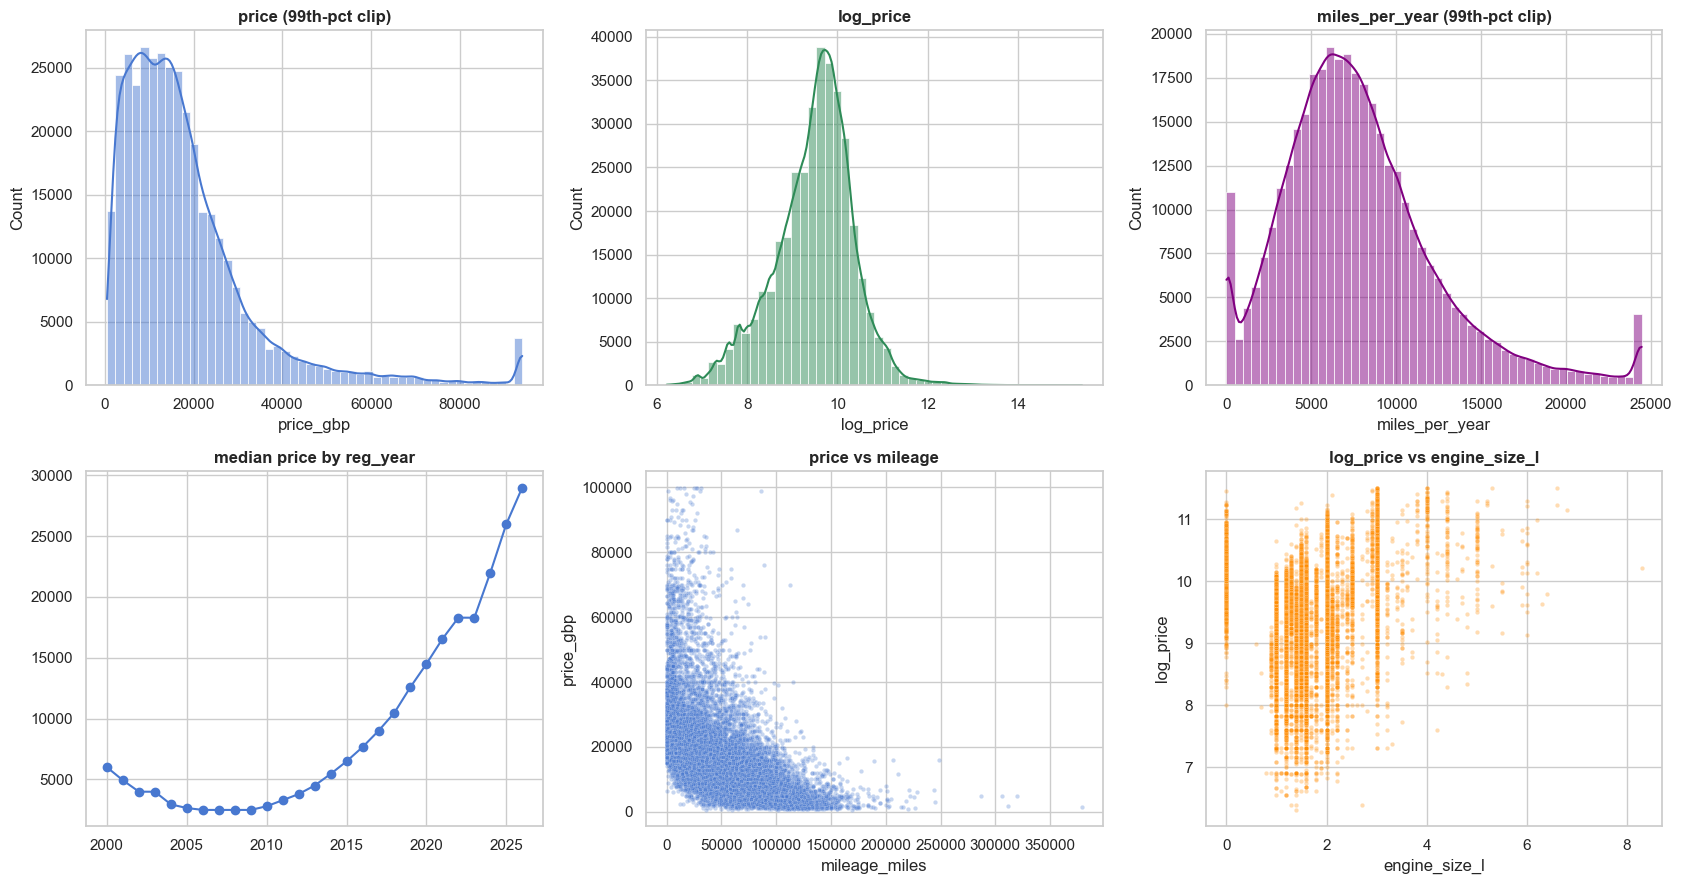

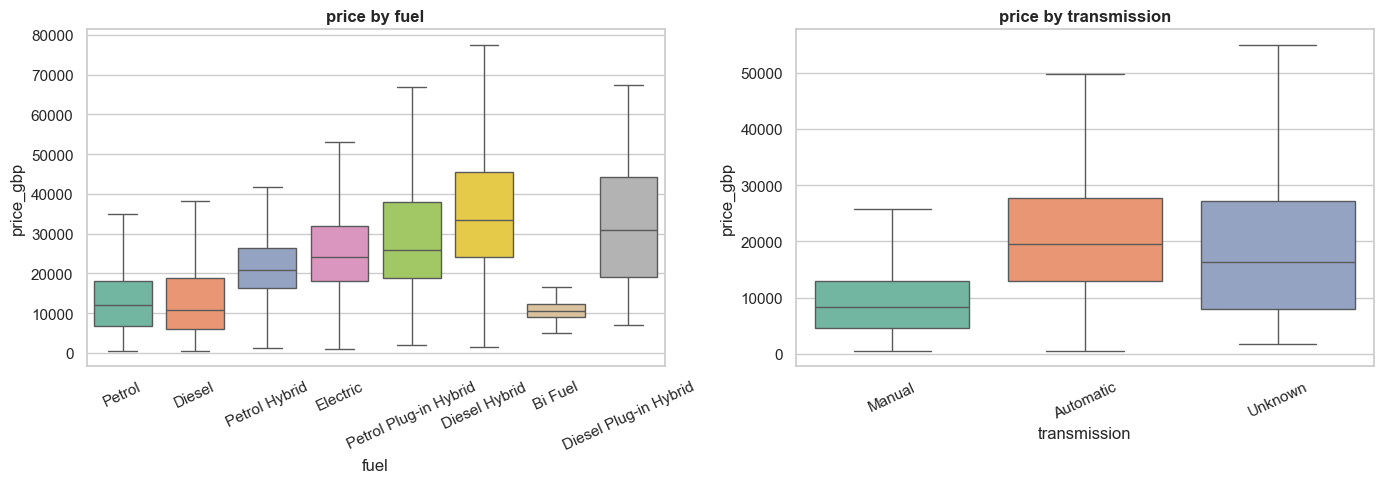

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
sns.histplot(df['price_gbp'].clip(upper=df.price_gbp.quantile(.99)), bins=50, kde=True, ax=axes[0, 0]); axes[0, 0].set_title('price (99th-pct clip)', fontweight='bold')
sns.histplot(df['log_price'], bins=50, kde=True, ax=axes[0, 1], color='seagreen'); axes[0, 1].set_title('log_price', fontweight='bold')
sns.histplot(df['miles_per_year'].clip(upper=df.miles_per_year.quantile(.99)), bins=50, kde=True, ax=axes[0, 2], color='purple'); axes[0, 2].set_title('miles_per_year (99th-pct clip)', fontweight='bold')
ys = df[df.reg_year >= 2000].groupby('reg_year')['price_gbp'].median()
axes[1, 0].plot(ys.index, ys.values, marker='o'); axes[1, 0].set_title('median price by reg_year', fontweight='bold')
sm = df[df.price_gbp < 100_000].sample(min(15_000, len(df)), random_state=1)
sns.scatterplot(data=sm, x='mileage_miles', y='price_gbp', alpha=.3, s=10, ax=axes[1, 1]); axes[1, 1].set_title('price vs mileage', fontweight='bold')
sns.scatterplot(data=sm, x='engine_size_l', y='log_price', alpha=.3, s=10, ax=axes[1, 2], color='darkorange'); axes[1, 2].set_title('log_price vs engine_size_l', fontweight='bold')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, c in zip(axes, ['fuel', 'transmission']):
    top = df[c].value_counts().head(8).index
    sns.boxplot(data=df[df[c].isin(top) & (df.price_gbp < 100_000)], x=c, y='price_gbp', showfliers=False, ax=ax, palette='Set2')
    ax.set_title(f'price by {c}', fontweight='bold'); ax.tick_params(axis='x', rotation=25)
plt.tight_layout(); plt.show()

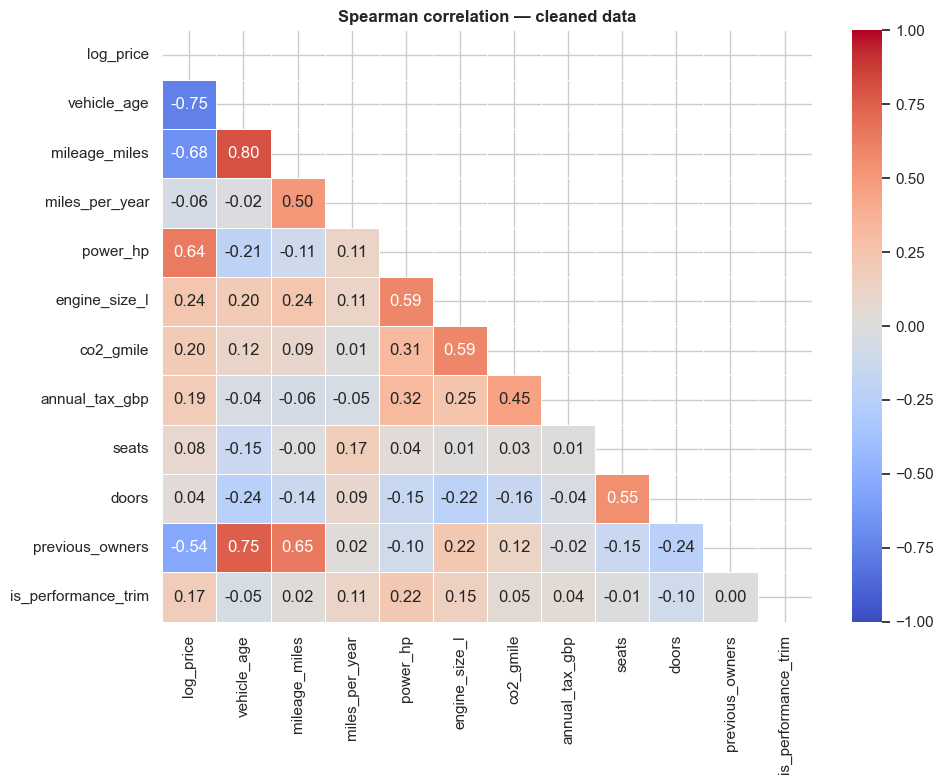

Strongest monotonic relationships with log_price:
vehicle_age           -0.75
mileage_miles         -0.68
power_hp               0.64
previous_owners       -0.54
engine_size_l          0.24
co2_gmile              0.20
annual_tax_gbp         0.19
is_performance_trim    0.17
seats                  0.08
miles_per_year        -0.06
doors                  0.04


In [23]:
corr_cols = ['log_price', 'vehicle_age', 'mileage_miles', 'miles_per_year', 'power_hp', 'engine_size_l',
             'co2_gmile', 'annual_tax_gbp', 'seats', 'doors', 'previous_owners', 'is_performance_trim']
corr2 = df[corr_cols].corr(method='spearman')
plt.figure(figsize=(10, 8))
sns.heatmap(corr2, mask=np.triu(np.ones_like(corr2, dtype=bool)), annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, linewidths=.5)
plt.title('Spearman correlation — cleaned data', fontweight='bold'); plt.tight_layout(); plt.show()
print('Strongest monotonic relationships with log_price:')
print(corr2['log_price'].drop('log_price').sort_values(key=abs, ascending=False).round(3).to_string())

### 4.4 Cleaning log

In [24]:
log_df = pd.DataFrame(clean_log)
display(log_df)
print(f'Total rows removed: {log_df.rows_removed.sum():,}')

,step,rows_removed,values_changed,detail
0,text_normalisation,0,1150,"unique labels {'make': 131, 'model': 1367, 'se..."
1,sentinel_to_nan,0,49487,"{'fuel': 191, 'transmission': 216, 'body_type'..."
2,drop_constant_columns,0,0,['condition']
3,drop_duplicates,886,0,exact duplicates after normalisation
4,drop_invalid_rows,91,0,"future/absurd year=0, placeholder price=1, pri..."
5,categorical_imputation,0,35663,inferred from version text / peers; remainder ...
6,mileage_fix,0,58,"0 miles on >=2-yr-old cars, or > MAX_MILEAGE"
7,power_fix,0,5964,0 hp or > MAX_REAL_HP on non-hypercars
8,co2_fix,0,31,"ICE zeros imputed=0, EV forced to 0=31"
9,previous_owners_fix,0,9426,0 owners on >=2-yr-old cars


Total rows removed: 1,204


In [25]:
# keep original column order first, then flags / derived columns
orig_cols = [c for c in df_raw.columns if c in df.columns]
new_cols = [c for c in df.columns if c not in orig_cols]
df_out = df[orig_cols + new_cols]

df_out.to_csv(OUT_PATH, index=False)
log_df.to_csv(LOG_PATH, index=False)

check = pd.read_csv(OUT_PATH)
assert check.shape == df_out.shape and check.isna().sum().sum() == 0
print(f'Saved {OUT_PATH}: {check.shape[0]:,} rows x {check.shape[1]} columns')
print(f'Saved {LOG_PATH}')
print('\nNew columns :', new_cols)
print('Drop before modelling (leaky/redundant): price_gbp if you train on log_price (or vice versa); version/seller_city are high-cardinality text.')
check.head()

Saved used_cars_cleaned_08.csv: 361,590 rows x 33 columns
Saved cleaning_log_08.csv

New columns : ['vehicle_age', 'emission_class_imputed', 'mileage_imputed', 'power_hp_imputed', 'co2_imputed', 'previous_owners_imputed', 'log_price', 'miles_per_year', 'engine_size_l', 'is_performance_trim', 'is_high_value', 'is_classic']
Drop before modelling (leaky/redundant): price_gbp if you train on log_price (or vice versa); version/seller_city are high-cardinality text.


,make,model,version,price_gbp,mileage_miles,reg_year,fuel,transmission,power_hp,body_type,body_color,doors,seats,previous_owners,drivetrain,emission_class,annual_tax_gbp,seller_type,seller_city,seller_county,co2_gmile,vehicle_age,emission_class_imputed,mileage_imputed,power_hp_imputed,co2_imputed,previous_owners_imputed,log_price,miles_per_year,engine_size_l,is_performance_trim,is_high_value,is_classic
0,Volkswagen,Polo,1.0 EVO Life Euro 6 (s/s) 5dr,13590,27685,2022,Petrol,Manual,79,Hatchback,Grey,5,5,2,Front Wheel Drive,Euro 6,200.00,Trade,New Southgate,Middlesex,198,4,0,0,0,0,0,9.52,"6,921.20",1.00,0,0,0
1,BMW,X5,3.0d Sport Auto 4WD Euro 4 5dr,995,119000,2003,Diesel,Automatic,181,SUV,Black,5,5,4,Four Wheel Drive,Euro 4,445.00,Trade,Northolt,Middlesex,417,23,0,0,0,0,0,6.90,"5,173.90",3.00,0,0,0
2,Audi,S3,2.0 TFSI Sportback S Tronic quattro Euro 6 (s/...,16490,70000,2016,Petrol,Automatic,306,Hatchback,Grey,5,5,4,Four Wheel Drive,Euro 6,225.00,Trade,Canterbury,Kent,240,10,0,0,0,0,0,9.71,"7,000.00",2.00,0,0,0
3,Volvo,XC40,2.0 B3 MHEV Plus Black Edition DCT Auto Euro 6...,31250,4767,2026,Petrol Hybrid,Automatic,161,SUV,Blue,5,5,1,Front Wheel Drive,Euro 6,200.00,Trade,Northampton,Northamptonshire,245,0,0,0,0,0,0,10.35,"4,767.00",2.00,0,0,0
4,Nissan,X-Trail,2.0 dCi Tekna Auto 4WD Euro 5 5dr (AVM),5500,107000,2014,Diesel,Automatic,148,SUV,Grey,5,5,4,Four Wheel Drive,Euro 5,410.00,Trade,Exmouth,Devon,303,12,0,0,0,0,0,8.61,"8,916.70",2.00,0,0,0
